# Homework 11


**Concepts covered:**

pandas `DataFrame`s: grouping data, querying `DataFrame`s, joining multiple `DataFrame`s, sampling.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning about AI:**

It is **strictly forbidden to use any generative AI (e.g., ChatGPT, Claude, Gemini, CoPilot or any similar tools**) to write solutions for any assignment. Students who submit work that is not authentically their own individual work will earn a grade of 0 on this assignment.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [1]:
# shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.close("all")


**Note: This assignment is partially manually graded, so please allow some time for you to get your final scores.**

**Review Problem 1**

**Concept:** *`DataFrame`: initialization, line plots.*

**Task:**


Using the Starbucks stock dataset:

1. Load the `SBUX.csv` dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Create a line plot showing both the `high` and `low` prices over time.

Your plot should include:

* both high and low columns plotted together
* a title
* a key


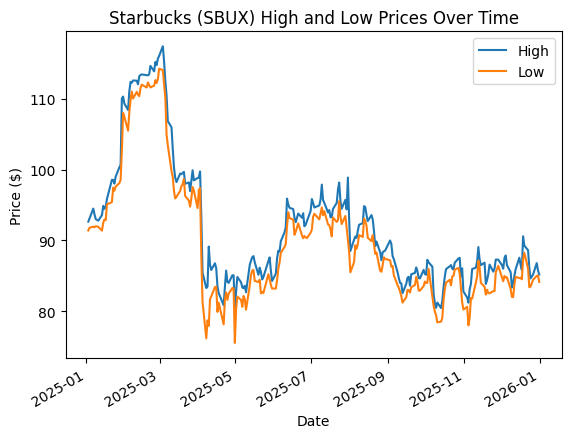

In [2]:
# Load SBUX data and convert the Unix timestamp date column to a DatetimeIndex.
df_sbux = pd.read_csv("SBUX.csv")
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s")
df_sbux = df_sbux.set_index("date")

# Plot both daily high and low prices together with a title and legend (key).
df_sbux[["high", "low"]].plot(title="Starbucks (SBUX) High and Low Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend(["High", "Low"])
plt.show()


Review Problem 2

**Concept:** *`DataFrame`: initialization, descriptive statistics, histogram.*

**Task:**

Using the `SBUX.csv` dataset:

1. Load the dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Compute the **daily return** of the stock using the `close` column (percentage change).
4. Display the **descriptive statistics** of the daily returns.
5. Create a **histogram** of the daily returns using 25 bins.
6. Identify **outliers** where the return falls outside of **mean ± 3 standard deviations**.
7. Print:
    *  the upper and lower bounds
    * the number of values above and below these bounds
    * the list of outlier values (sorted by date)


Descriptive Statistics of SBUX Daily Returns:
count    249.000000
mean      -0.000130
std        0.021601
min       -0.112162
25%       -0.011336
50%        0.000107
75%        0.011323
max        0.112812
Name: close, dtype: float64


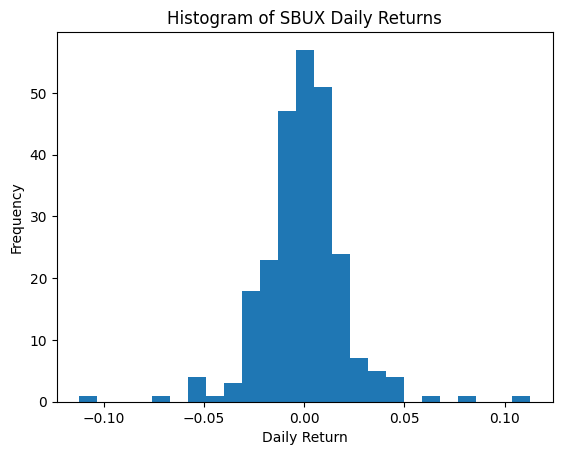

Lower bound: -0.064932
Upper bound: 0.064672
Number of values above upper bound: 3
Number of values below lower bound: 2
Outlier values (sorted by date):
date
2025-01-29 14:30:00    0.081366
2025-04-03 13:30:00   -0.112162
2025-04-04 13:30:00   -0.069794
2025-04-09 13:30:00    0.112812
2025-05-12 13:30:00    0.066874
Name: close, dtype: float64


In [3]:
# Load SBUX data and convert the Unix timestamp date column to a DatetimeIndex.
df_sbux = pd.read_csv("SBUX.csv")
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s")
df_sbux = df_sbux.set_index("date")

# Compute daily percentage returns from the close price and drop the initial NaN.
daily_returns = df_sbux["close"].pct_change().dropna()

# Display descriptive statistics for daily returns.
print("Descriptive Statistics of SBUX Daily Returns:")
print(daily_returns.describe())

# Plot a histogram of daily returns with 25 bins.
plt.figure()
plt.hist(daily_returns, bins=25)
plt.title("Histogram of SBUX Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()

# Compute mean +/- 3 standard deviations bounds to identify outliers.
mean_return = daily_returns.mean()
std_return = daily_returns.std()
lower_bound = mean_return - 3 * std_return
upper_bound = mean_return + 3 * std_return

# Separate returns above the upper bound and below the lower bound.
above_outliers = daily_returns[daily_returns > upper_bound]
below_outliers = daily_returns[daily_returns < lower_bound]
outliers = daily_returns[(daily_returns > upper_bound) | (daily_returns < lower_bound)].sort_index()

print(f"Lower bound: {lower_bound:.6f}")
print(f"Upper bound: {upper_bound:.6f}")
print(f"Number of values above upper bound: {len(above_outliers)}")
print(f"Number of values below lower bound: {len(below_outliers)}")
print("Outlier values (sorted by date):")
print(outliers)


Test case for problem 2

In [4]:
# Test Case:
assert isinstance(df_sbux.index, pd.DatetimeIndex), "df_sbux index must be a DatetimeIndex"
assert len(daily_returns) == len(df_sbux) - 1, "daily_returns should have one fewer row than df_sbux"
assert len(outliers) == len(above_outliers) + len(below_outliers), "Total outliers must match above + below"
print("Review Problem 2 checks passed.")


Review Problem 2 checks passed.


**Problem 3**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Load the dataset into a DataFrame named `df_weather`.
2. Convert the `datetime` column to a pandas datetime format and set it as the index.
3. Use the icon column as a categorical variable and group the data by `icon`.
4. Create a **pie chart** showing the count of each weather icon category.

Your chart should include:
* labels for each category
* a title



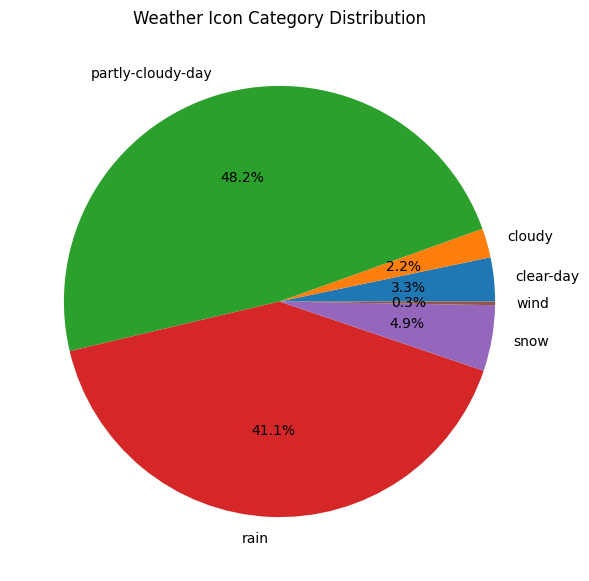

In [5]:
# Load weather data, parse datetime, and set it as the index.
df_weather = pd.read_csv("02215_weather.csv")
df_weather["datetime"] = pd.to_datetime(df_weather["datetime"], format="%m/%d/%y")
df_weather = df_weather.set_index("datetime")

# Group the DataFrame by the categorical icon column.
grouped_by_icon = df_weather.groupby("icon")

# Count days per weather icon category and display a pie chart.
icon_counts = grouped_by_icon.size()
plt.figure(figsize=(7, 7))
plt.pie(icon_counts, labels=icon_counts.index, autopct="%1.1f%%")
plt.title("Weather Icon Category Distribution")
plt.show()


**Problem 4**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a **histogram** of the `tempmax` column for each weather condition group.

Your plot should include:
* 25 bins
* transparency so overlapping distributions can be seen
* a legend
* a title


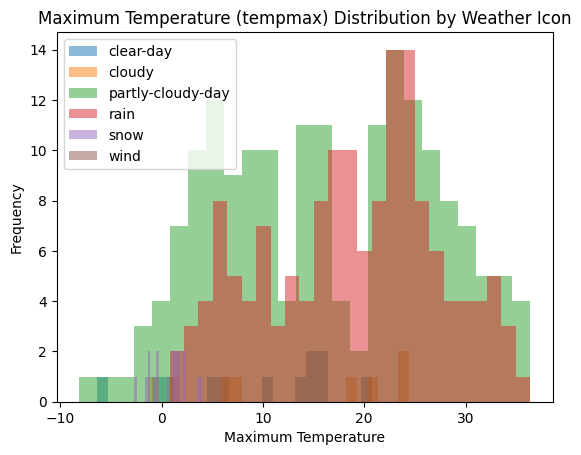

In [6]:
# Plot overlapping histograms of tempmax for each weather icon group.
plt.figure()
grouped_by_icon["tempmax"].plot(kind="hist", bins=25, alpha=0.5, legend=True)
plt.title("Maximum Temperature (tempmax) Distribution by Weather Icon")
plt.xlabel("Maximum Temperature")
plt.ylabel("Frequency")
plt.show()


**Problem 5**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a histogram of the `precip` column for each weather condition group.

Your plot should include:

* 10 bins
* transparency so overlapping distributions can be seen
* a legend
* a title



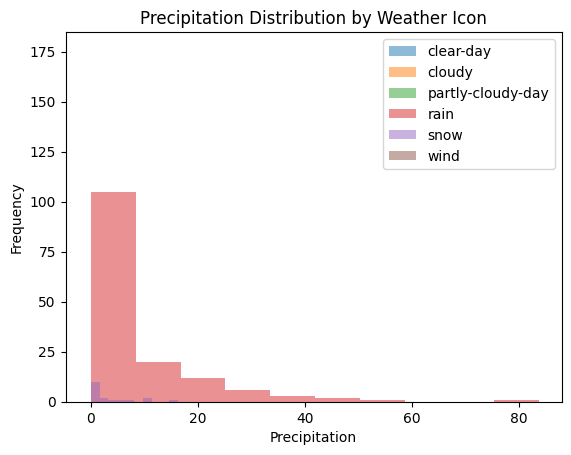

In [7]:
# Plot overlapping histograms of precip for each weather icon group.
plt.figure()
grouped_by_icon["precip"].plot(kind="hist", bins=10, alpha=0.5, legend=True)
plt.title("Precipitation Distribution by Weather Icon")
plt.xlabel("Precipitation")
plt.ylabel("Frequency")
plt.show()


**Problem 6**

**Concept:** *Grouping Data, plotting*


**Task:**


Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Compute the **mean** of the `tempmax` column for each weather condition group.
3. Create a **bar chart** to display the mean maximum temperature for each group.


Your plot should include:

* one bar for each weather icon category
* a title



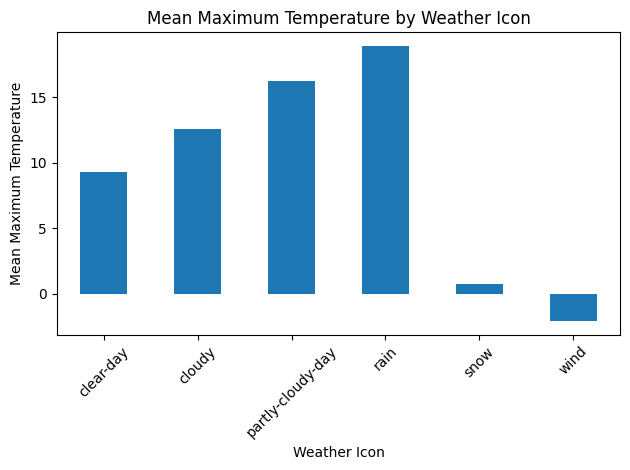

In [8]:
# Compute mean tempmax per weather icon group and display a bar chart.
mean_tempmax_by_icon = grouped_by_icon["tempmax"].mean()
plt.figure()
mean_tempmax_by_icon.plot(kind="bar", title="Mean Maximum Temperature by Weather Icon")
plt.xlabel("Weather Icon")
plt.ylabel("Mean Maximum Temperature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Problem 7**

**Concept:** *Grouping data, descriptive statistics*


**Task:**

Using the `02215_weather.csv` dataset:

1. Group the DataFrame by the `icon` column and store the result in a variable named `grouped_by_icon`.
2. Compute descriptive statistics for the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_statistics`.
3. Compute descriptive statistics for the `precip` column for each group and store the result in a variable named `grouped_precipitation_statistics`.
4. Compute the **mean** of the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_mean`.

Print all three results with clear labels:
* `"Tempmax grouped by conditions"`
* `"Precipitation grouped by conditions"`
* `"Mean of tempmax grouped by conditions"`


In [9]:
# Reload weather data and group by icon (keeping standard string Index rather than CategoricalIndex).
df_weather = pd.read_csv("02215_weather.csv")
df_weather["datetime"] = pd.to_datetime(df_weather["datetime"], format="%m/%d/%y")
df_weather = df_weather.set_index("datetime")

grouped_by_icon = df_weather.groupby("icon")
grouped_tempmax_statistics = grouped_by_icon["tempmax"].describe()
grouped_precipitation_statistics = grouped_by_icon["precip"].describe()
grouped_tempmax_mean = grouped_by_icon["tempmax"].mean()

print("Tempmax grouped by conditions")
print(grouped_tempmax_statistics)
print()
print("Precipitation grouped by conditions")
print(grouped_precipitation_statistics)
print()
print("Mean of tempmax grouped by conditions")
print(grouped_tempmax_mean)


Tempmax grouped by conditions
                   count       mean        std  min    25%    50%     75%  \
icon                                                                        
clear-day           12.0   9.316667   8.230965 -6.4   4.15  12.10  15.225   
cloudy               8.0  12.575000  10.423565 -1.3   4.95  13.05  21.350   
partly-cloudy-day  176.0  16.246023  10.533554 -8.1   7.20  15.65  25.000   
rain               150.0  18.904000   8.498037  0.8  12.60  19.90  24.600   
snow                18.0   0.750000   1.805628 -2.7  -0.65   1.25   1.775   
wind                 1.0  -2.100000        NaN -2.1  -2.10  -2.10  -2.100   

                    max  
icon                     
clear-day          20.8  
cloudy             24.4  
partly-cloudy-day  36.4  
rain               36.4  
snow                4.0  
wind               -2.1  

Precipitation grouped by conditions
                   count      mean        std    min      25%     50%  \
icon                               

QUERYING

The following data frame will be used in several questions.


In [10]:
# starter code
df_voter_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv", low_memory=False)
df_voter_data.index = df_voter_data["Voter ID Number"]
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])


**Problem 8**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Determine the **total number of voters** and print the result.
2. Compute the count of voters in each **Party Affiliation** category.
3. Create a **pie chart** showing the distribution of voters by party affiliation.

Your plot should include:
* labels for each category
* a title that includes the total number of voters


Total number of voters: 58769


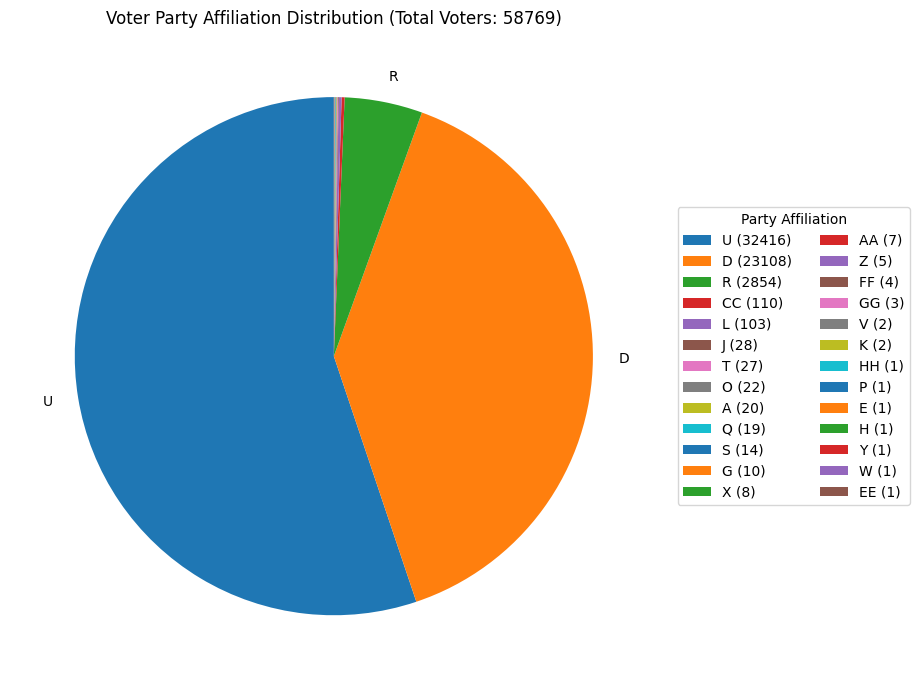

In [11]:
# Compute total voter count and distribution by Party Affiliation.
total_voters = len(df_voter_data)
print("Total number of voters:", total_voters)

party_counts = df_voter_data["Party Affiliation"].value_counts()

# Show direct slice labels only for major parties (>= 1%) and list all categories in a legend to avoid overlap.
slice_labels = [
    party.strip() if count / total_voters >= 0.01 else ""
    for party, count in party_counts.items()
]
legend_labels = [f"{party.strip()} ({count})" for party, count in party_counts.items()]

plt.figure(figsize=(10, 7))
wedges, _ = plt.pie(party_counts, labels=slice_labels, startangle=90)
plt.legend(
    wedges,
    legend_labels,
    title="Party Affiliation",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=2,
)
plt.title(f"Voter Party Affiliation Distribution (Total Voters: {total_voters})")
plt.tight_layout()
plt.show()


**Problem 9**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_older_voters` that includes only voters born **before January 1, 1950**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these older voters.

Your plot should include:
* labels for each category
* a title that includes the number of older voters


Total number of older voters (born before 1950-01-01): 9073


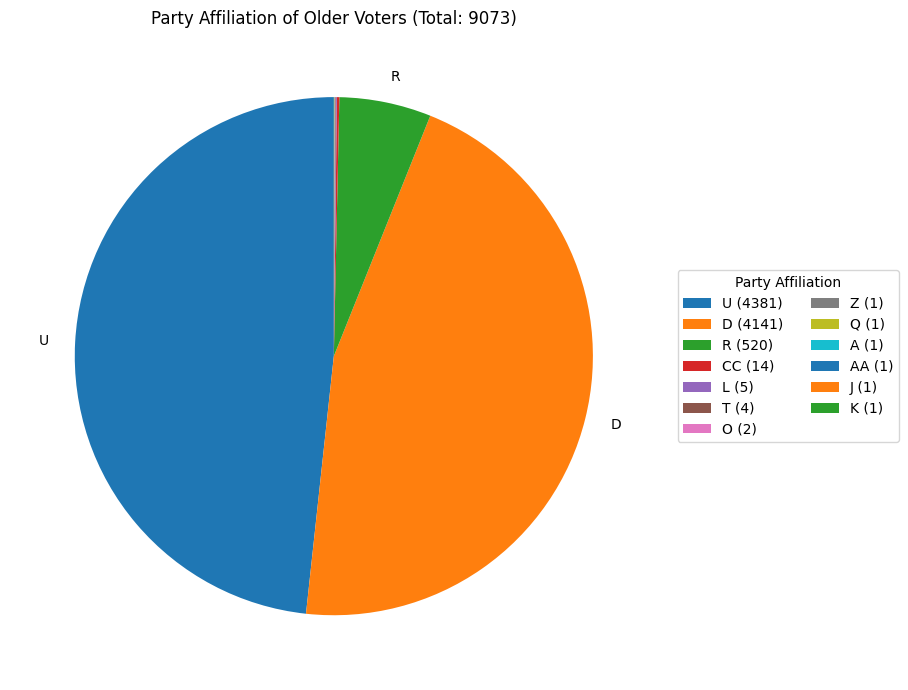

In [12]:
# Filter voters born before January 1, 1950 using .query().
df_older_voters = df_voter_data.query("`Date of Birth` < '1950-01-01'")
num_older_voters = len(df_older_voters)
print("Total number of older voters (born before 1950-01-01):", num_older_voters)

# Compute party affiliation counts and plot a pie chart for older voters.
older_party_counts = df_older_voters["Party Affiliation"].value_counts()
slice_labels = [
    party.strip() if count / num_older_voters >= 0.01 else ""
    for party, count in older_party_counts.items()
]
legend_labels = [f"{party.strip()} ({count})" for party, count in older_party_counts.items()]

plt.figure(figsize=(10, 7))
wedges, _ = plt.pie(older_party_counts, labels=slice_labels, startangle=90)
plt.legend(
    wedges,
    legend_labels,
    title="Party Affiliation",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=2,
)
plt.title(f"Party Affiliation of Older Voters (Total: {num_older_voters})")
plt.tight_layout()
plt.show()


**Problem 10**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_younger_voters` that includes only voters born **after January 1, 2000**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these Younger voters.

Your plot should include:
* labels for each category
* a title that includes the number of younger voters


Total number of younger voters (born after 2000-01-01): 5099


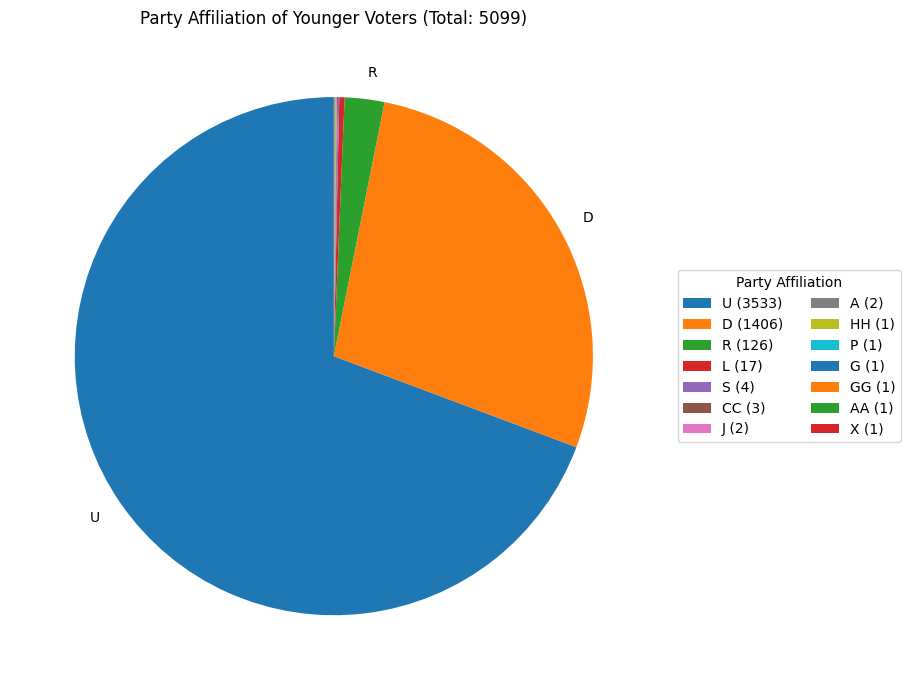

In [13]:
# Filter voters born after January 1, 2000 using .query().
df_younger_voters = df_voter_data.query("`Date of Birth` > '2000-01-01'")
num_younger_voters = len(df_younger_voters)
print("Total number of younger voters (born after 2000-01-01):", num_younger_voters)

# Compute party affiliation counts and plot a pie chart for younger voters.
younger_party_counts = df_younger_voters["Party Affiliation"].value_counts()
slice_labels = [
    party.strip() if count / num_younger_voters >= 0.01 else ""
    for party, count in younger_party_counts.items()
]
legend_labels = [f"{party.strip()} ({count})" for party, count in younger_party_counts.items()]

plt.figure(figsize=(10, 7))
wedges, _ = plt.pie(younger_party_counts, labels=slice_labels, startangle=90)
plt.legend(
    wedges,
    legend_labels,
    title="Party Affiliation",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=2,
)
plt.title(f"Party Affiliation of Younger Voters (Total: {num_younger_voters})")
plt.tight_layout()
plt.show()


**Problem 11**

**Concept:** *Querying `DataFrame`s and graphing*



**Task:**

Using the `df_voter_data` DataFrame:
1. Identify all columns related to elections:
    * Select columns whose names contain the letter `"v"` but do **not** contain `"score"`
    * Store the result in a variable named `election_columns`

2. Compute the **voting participation percentage** for each election among all voters:
    * Store the result in a variable named `d1`
    * **Hint:** To calculate participation
        * Use `.sum()` on a column to count how many voters participated
        * Divide by the total number of voters using `len(df)`
        * Multiply by 100 to convert to a percentage

3. Create a filtered DataFrame named `df_high_voter_score`:
    * Include only voters with `voter_score >= 4`
    * Print the number of voters in this group

4. Compute the **voting participation percentage** for this group:
    * Store the result in a variable named `d2`

5. Create a filtered DataFrame named `df_unenrolled`:
    * Include only voters with `"Party Affiliation" == "U "`
    * Print the number of voters in this group

6. Compute the voting participation percentage for this group:
    * Store the result in a variable named `d3`

7. Combine the results into a new DataFrame named `d`:
    * Index should be the election columns
    * Columns should be:
        * `"all voters"`
        * `"high-propensity voters"`
        * `"unenrolled voters"`

8. Create a **bar chart** from this combined DataFrame.

Your plot should include:
* a title
* a key

Number of high-propensity voters (voter_score >= 4): 15245
Number of unenrolled voters (Party Affiliation == 'U '): 32416


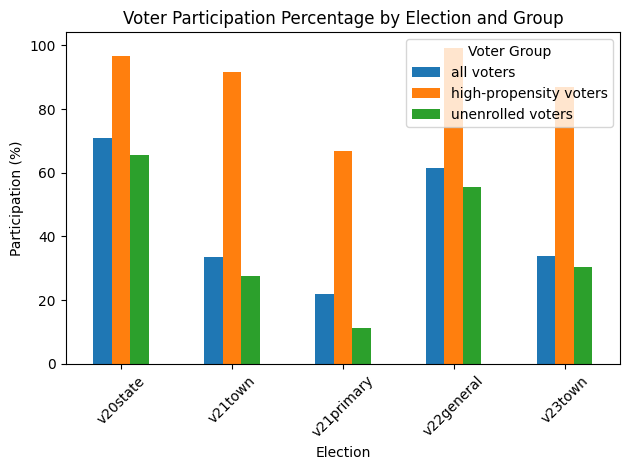

In [14]:
# Select election columns containing 'v' but not 'score'.
election_columns = [col for col in df_voter_data.columns if "v" in col and "score" not in col]

# Participation percentage across all voters.
d1 = df_voter_data[election_columns].sum() / len(df_voter_data) * 100

# Filter high-propensity voters (voter_score >= 4) and compute participation percentage.
df_high_voter_score = df_voter_data.query("voter_score >= 4")
print("Number of high-propensity voters (voter_score >= 4):", len(df_high_voter_score))
d2 = df_high_voter_score[election_columns].sum() / len(df_high_voter_score) * 100

# Filter unenrolled voters (Party Affiliation == 'U ') and compute participation percentage.
df_unenrolled = df_voter_data.query("`Party Affiliation` == 'U '")
print("Number of unenrolled voters (Party Affiliation == 'U '):", len(df_unenrolled))
d3 = df_unenrolled[election_columns].sum() / len(df_unenrolled) * 100

# Combine all three series into a single DataFrame indexed by election_columns.
d = pd.DataFrame(
    {
        "all voters": d1,
        "high-propensity voters": d2,
        "unenrolled voters": d3,
    },
    index=election_columns,
)

# Plot grouped bar chart with title and legend (key).
d.plot(kind="bar", title="Voter Participation Percentage by Election and Group")
plt.xlabel("Election")
plt.ylabel("Participation (%)")
plt.legend(title="Voter Group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Problem 12**

**Concept:** *Joining `DataFrame`s*


**Task:**

You are given two DataFrames:
* `submissions`, which contains student IDs and their homework submission IDs
* `grades`, which contains homework grades indexed by submission ID

Using these DataFrames:
1. Inspect both DataFrames by printing them.
2. Join the `submissions` DataFrame with the `grades` DataFrame:
    * Match the `hw1_submission` column in `submissions` with the index of `grades`
    * Store the result in a variable named `result`
3. Update the index of the resulting DataFrame:
    * Set the index to the `student_id` column
4. Create a new DataFrame named `result_df`:
    * Remove the `student_id` column
5. Print the final DataFrame


Starter code:

In [15]:
# STARTER CODE:
submissions = pd.DataFrame(data={"student_id": ["U100", "U101", "U102", "U103", "U104"],
                        "hw1_submission": ["c1325", "b231", "a512", "e9999", "d8234"]})

grades = pd.DataFrame(index=["a512", "b231", "c1325", "d8234", "e9999"],
                        data={"hw1_grade": [0.99, 0.50, 0.62, 0.78, 1.00]} )


In [16]:
# Inspect both input DataFrames.
print("Submissions:")
print(submissions)
print()
print("Grades:")
print(grades)
print()

# Join submissions with grades on hw1_submission matching the index of grades.
result = submissions.join(grades, on="hw1_submission")

# Set the index to student_id, then drop the student_id column to form result_df.
result.index = result["student_id"]
result_df = result.drop(columns=["student_id"])

print("Final result_df:")
print(result_df)


Submissions:
  student_id hw1_submission
0       U100          c1325
1       U101           b231
2       U102           a512
3       U103          e9999
4       U104          d8234

Grades:
       hw1_grade
a512        0.99
b231        0.50
c1325       0.62
d8234       0.78
e9999       1.00

Final result_df:
           hw1_submission  hw1_grade
student_id                          
U100                c1325       0.62
U101                 b231       0.50
U102                 a512       0.99
U103                e9999       1.00
U104                d8234       0.78


**Problem 13**

**Concept:** *Joining `DataFrame`s*



**Task:**

You are given two datasets:
* `design_materials.tsv`, which contains materials and the quantity required per bed
* `material_costs.tsv`, which contains the cost per unit for each material

Using these datasets:
1. Load both datasets from the provided `.tsv` files using the correct separator.
2. Merge the two DataFrames:
    * Join on the `material` column
    * Store the result in a variable named `df_costs`
3. Create a new column named `cost`:
    * Compute it as:

      **quantity_per_bed × unit_cost**
4. Print the resulting DataFrame

In [17]:
# Load both TSV datasets using tab separator.
df_design_materials = pd.read_csv("design_materials.tsv", sep="\t")
df_material_costs = pd.read_csv("material_costs.tsv", sep="\t")

# Merge on the shared material column and compute total cost per bed.
df_costs = pd.merge(df_design_materials, df_material_costs, on="material")
df_costs["cost"] = df_costs["quantity_per_bed"] * df_costs["unit_cost"]

print(df_costs)


          design                    material  quantity_per_bed  unit_cost  \
0  4' x 4' x 18"                2" x 6" x 4'                20       5.92   
1  4' x 4' x 18"  8" x 8" x 16" Cinder Block                12       3.53   
2  4' x 8' x 18"                2" x 6" x 4'                 6       5.92   
3  4' x 8' x 18"                2" x 6" x 8'                14       7.62   
4  4' x 8' x 18"  8" x 8" x 16" Cinder Block                24       3.53   
5  4' x 4' x 12"                2" x 6" x 4'                16       5.92   
6  4' x 4' x 12"  8" x 8" x 16" Cinder Block                12       3.53   
7  4' x 8' x 12"                2" x 6" x 4'                 2       5.92   
8  4' x 8' x 12"                2" x 6" x 8'                12       7.62   
9  4' x 8' x 12"  8" x 8" x 16" Cinder Block                24       3.53   

     cost  
0  118.40  
1   42.36  
2   35.52  
3  106.68  
4   84.72  
5   94.72  
6   42.36  
7   11.84  
8   91.44  
9   84.72  


**Problem 14**

**Concept:** *joining `DataFrame`s*


**Task:**

You are given three stock datasets:
* BAC
* GM
* SBUX

Using these datasets:
1. Load each dataset into separate DataFrames:
    * `df_bac`, `df_gm`, and `df_sbux`
2. Convert the `date` column in each DataFrame to pandas datetime format and set it as the index.
3. Create a new DataFrame named `df_stock_prices`:
    * Use the index from `df_bac`
    * Add the following columns:
        * `"bac"` from `df_bac["close"]`
        * `"gm"` from `df_gm["close"]`
        * `"sbux"` from `df_sbux["close"]`
4. Create a **line plot** showing the stock prices over time.

Your plot should include:
* all three stocks on the same chart
* a title

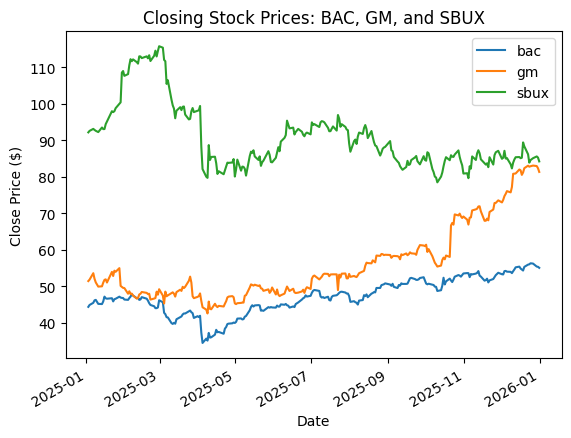

In [18]:
# Load stock CSVs and convert Unix timestamp dates to DatetimeIndex.
df_bac = pd.read_csv("BAC.csv")
df_bac["date"] = pd.to_datetime(df_bac["date"], unit="s")
df_bac = df_bac.set_index("date")

df_gm = pd.read_csv("GM.csv")
df_gm["date"] = pd.to_datetime(df_gm["date"], unit="s")
df_gm = df_gm.set_index("date")

df_sbux = pd.read_csv("SBUX.csv")
df_sbux["date"] = pd.to_datetime(df_sbux["date"], unit="s")
df_sbux = df_sbux.set_index("date")

# Combine closing prices into a single DataFrame indexed by df_bac's dates.
df_stock_prices = pd.DataFrame(index=df_bac.index)
df_stock_prices["bac"] = df_bac["close"]
df_stock_prices["gm"] = df_gm["close"]
df_stock_prices["sbux"] = df_sbux["close"]

# Line plot of all three closing prices over time.
df_stock_prices.plot(title="Closing Stock Prices: BAC, GM, and SBUX")
plt.xlabel("Date")
plt.ylabel("Close Price ($)")
plt.show()


**Problem 15**

**Concept:** *joining `DataFrame`s*


**Task:**

Using the `df_stock_prices` DataFrame from **Problem 14**:
1. Compute the **relative prices** of each stock:
    * Divide all values by the first row of the DataFrame
    * Store the result in a variable named `df_stock_prices_relative`
2. Create a **line plot** of the relative prices.

Your plot should include:
* all three stocks on the same chart
* a title

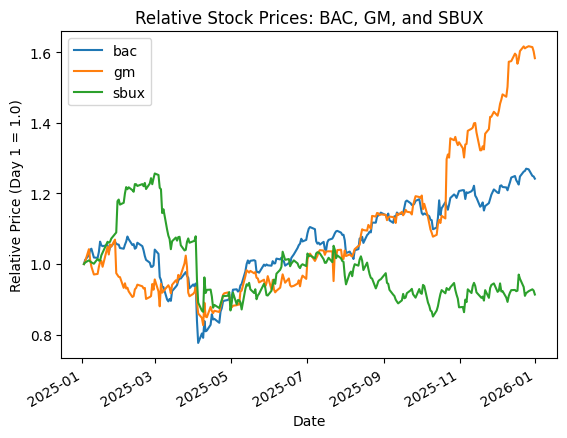

In [19]:
# Normalize each stock's price series by dividing by the first row.
df_stock_prices_relative = df_stock_prices / df_stock_prices.iloc[0]

# Line plot of relative prices over time.
df_stock_prices_relative.plot(title="Relative Stock Prices: BAC, GM, and SBUX")
plt.xlabel("Date")
plt.ylabel("Relative Price (Day 1 = 1.0)")
plt.show()
